# CSIS 604 Team Project — Raft Simulation

**Project:** Empirical Analysis of Raft Consensus under Network Stress

**Team Members:**
- Christian Soto
- Dan Johnson

**Course:** CSIS 604 — Distributed Systems

---



## Exercise 1 — Latency Spikes & Split-Brain Elections

### Network Latency vs. Election Frequency

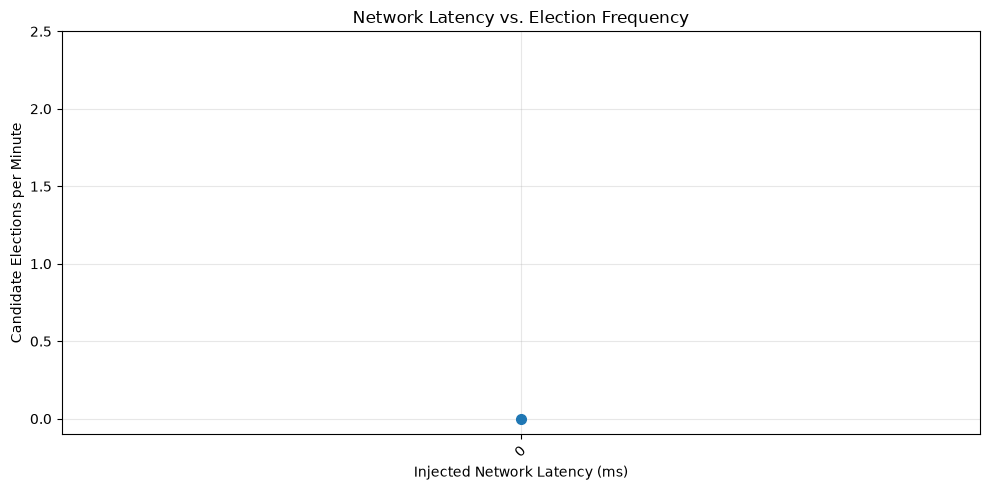

In [18]:
import matplotlib.pyplot as plt
import numpy as np

#can easily enter data here
latency_ms = [0]
elections_per_min = [0]

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    latency_ms,
    elections_per_min,
    marker="o",
    linewidth=2,
    markersize=7
)

ax.set_title("Network Latency vs. Election Frequency")
ax.set_xlabel("Injected Network Latency (ms)")
ax.set_ylabel("Candidate Elections per Minute")

ax.set_xticks(latency_ms)
ax.tick_params(axis="x", rotation=45)
ax.set_ylim(-0.1, 2.5)
ax.grid(alpha=0.3)

ax.annotate(
    "Unavailable",
    xy=(3000, 0),
    xytext=(2700, 0.6),
    arrowprops=dict(arrowstyle="->")
)

plt.tight_layout()
plt.savefig("exercise1_election_frequency.png", dpi=200)
plt.show()


### Exercise 1 — Analysis

**PLACEHOLDER**


---

## Exercise 2 — Minority Partition & Uncommitted Log Tracing

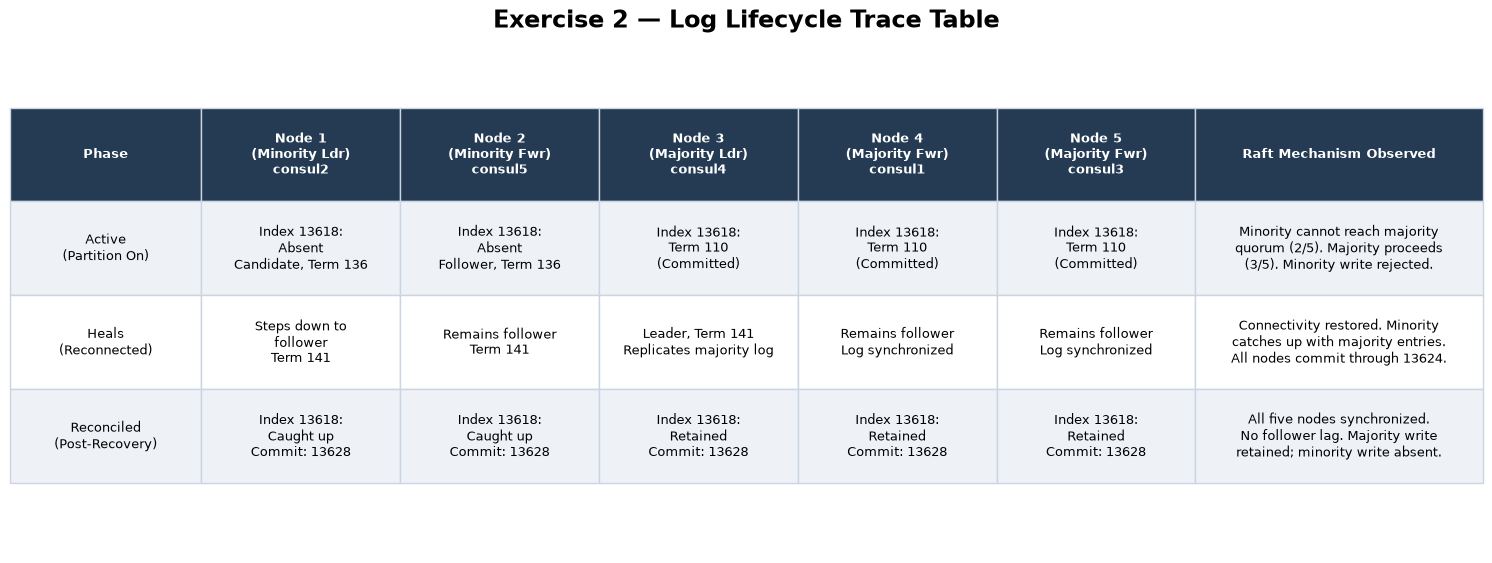

In [14]:
import matplotlib.pyplot as plt

columns = [
    "Phase",
    "Node 1\n(Minority Ldr)\nconsul2",
    "Node 2\n(Minority Fwr)\nconsul5",
    "Node 3\n(Majority Ldr)\nconsul4",
    "Node 4\n(Majority Fwr)\nconsul1",
    "Node 5\n(Majority Fwr)\nconsul3",
    "Raft Mechanism Observed"
]

rows = [
    [
        "Active\n(Partition On)",
        "Index 13618:\nAbsent\nCandidate, Term 136",
        "Index 13618:\nAbsent\nFollower, Term 136",
        "Index 13618:\nTerm 110\n(Committed)",
        "Index 13618:\nTerm 110\n(Committed)",
        "Index 13618:\nTerm 110\n(Committed)",
        "Minority cannot reach majority\n"
        "quorum (2/5). Majority proceeds\n"
        "(3/5). Minority write rejected."
    ],
    [
        "Heals\n(Reconnected)",
        "Steps down to\nfollower\nTerm 141",
        "Remains follower\nTerm 141",
        "Leader, Term 141\nReplicates majority log",
        "Remains follower\nLog synchronized",
        "Remains follower\nLog synchronized",
        "Connectivity restored. Minority\n"
        "catches up with majority entries.\n"
        "All nodes commit through 13624."
    ],
    [
        "Reconciled\n(Post-Recovery)",
        "Index 13618:\nCaught up\nCommit: 13628",
        "Index 13618:\nCaught up\nCommit: 13628",
        "Index 13618:\nRetained\nCommit: 13628",
        "Index 13618:\nRetained\nCommit: 13628",
        "Index 13618:\nRetained\nCommit: 13628",
        "All five nodes synchronized.\n"
        "No follower lag. Majority write\n"
        "retained; minority write absent."
    ]
]

fig, ax = plt.subplots(figsize=(19, 6.5))
ax.axis("off")

ax.set_title(
    "Exercise 2 — Log Lifecycle Trace Table",
    fontsize=17, fontweight="bold", pad=18
)

table = ax.table(
    cellText=rows,
    colLabels=columns,
    colWidths=[0.13, 0.135, 0.135, 0.135, 0.135, 0.135, 0.195],
    cellLoc="center",
    loc="center",
    bbox=[0, 0.14, 1, 0.75]
)

table.auto_set_font_size(False)
table.set_fontsize(9)

for (r, c), cell in table.get_celld().items():
    cell.set_edgecolor("#CBD5E1")
    if r == 0:
        cell.set_facecolor("#243B53")
        cell.set_text_props(color="white", weight="bold")
    else:
        cell.set_facecolor("#EEF2F7" if r % 2 else "white")
        cell.set_text_props(va="center")

plt.show()

### Exercise 2 — Analysis

The five-node Consul cluster was divided into a three-node majority (`consul1`, `consul3`, and `consul4`) and a two-node minority (`consul2` and `consul5`). The partition separated the original leader, `consul2`, from the majority. KV writes were attempted on both sides to observe how Raft handles the loss of a majority quorum.

**Active (Partition On):** The majority elected `consul4` as its new leader and committed entries through log index 13618 with term 110. The minority remained at index 13586 with its last log term at 107. `consul2` entered candidate state because it could no longer maintain leadership without a majority quorum. The majority write succeeded while the minority write returned "No cluster leader."

**Heals (Reconnected):** Network communication was restored and the minority nodes rejoined the cluster as followers. All five nodes reached log and commit index 13624 with term 141. This showed that the minority had caught up with the entries committed by the majority during the partition.

**Reconciled (Post-Recovery):** All five nodes eventually reached commit index 13628 with no replication lag. `consul2` regained leadership and the majority write remained available. The minority write was not committed.

Log index 13618 was used to trace the difference between the two groups. The majority committed this entry while the minority was unable to make progress. Raft synchronized the logs after connectivity was restored. The experiment demonstrated log recovery through replication rather than the replacement of a conflicting uncommitted entry, which was not observed.

---

## Exercise 3 — Packet Loss & Throughput Degradation

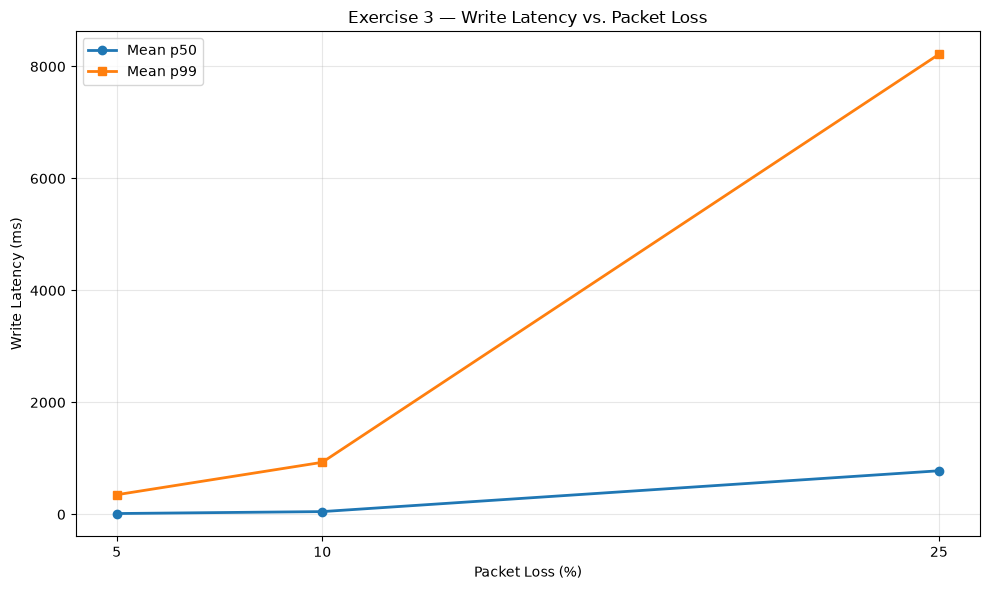

In [15]:
import matplotlib.pyplot as plt
import numpy as np

loss = np.array([5, 10, 25])

p50 = np.array([
    [14.10, 14.70, 15.82],
    [41.59, 62.42, 44.48],
    [972.78, 695.10, 668.10]
])

p99 = np.array([
    [267.62, 504.47, 279.79],
    [652.40, 1369.59, 768.05],
    [5650.17, 9742.00, 9260.92]
])

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    loss, p50.mean(axis=1),
    marker="o", linewidth=2,
    label="Mean p50"
)

ax.plot(
    loss, p99.mean(axis=1),
    marker="s", linewidth=2,
    label="Mean p99"
)

ax.set_title("Exercise 3 — Write Latency vs. Packet Loss")
ax.set_xlabel("Packet Loss (%)")
ax.set_ylabel("Write Latency (ms)")
ax.set_xticks(loss)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


### Exercise 3 — Analysis

The results show that increasing packet loss significantly affected write latency. Average p50 latency increased from 14.87 ms at 5% packet loss to 778.66 ms at 25%, while average p99 increased from 350.63 ms to 8217.70 ms.

The difference occurs because p50 represents the median write request, while p99 represents requests experiencing the longest delays. Packet loss does not affect every request equally. Affected requests experience TCP retransmissions, repeated packet loss, or delays waiting for Raft replication to reach a majority quorum. These delays accumulate for the slowest requests, causing p99 to increase much more sharply in absolute latency than p50.

At 25% packet loss, 431 of 3000 write attempts failed, primarily due to timeouts. These failures were excluded from the latency percentiles because their successful completion times could not be measured. Consequently, the reported p99 represents only successful writes and may understate the overall impact of packet loss.

The experiment demonstrates that Raft can continue processing writes under significant packet loss, but its tail latency and write reliability deteriorate as network conditions worsen.